MCMC Chain Approaching Max value of the function

No of points you want to take: 100000

Acceptance Rate: 87.17%


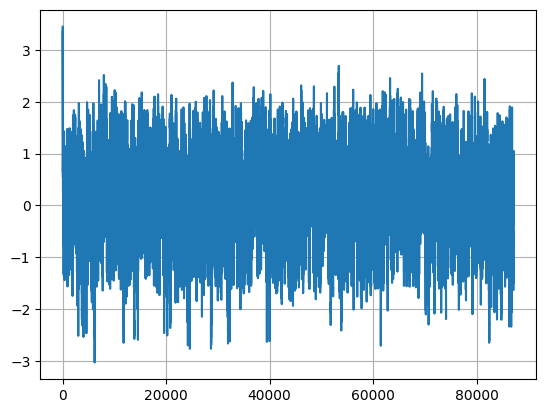

 True Maximum of f(x): 4.1761 at x = 0.2800
 Max Sampled f(x): 4.1761 at x = 0.2804


/tmp/ipython-input-1-3637167905.py:88: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  normalized_y1 = y1 / np.trapz(y1, x1)


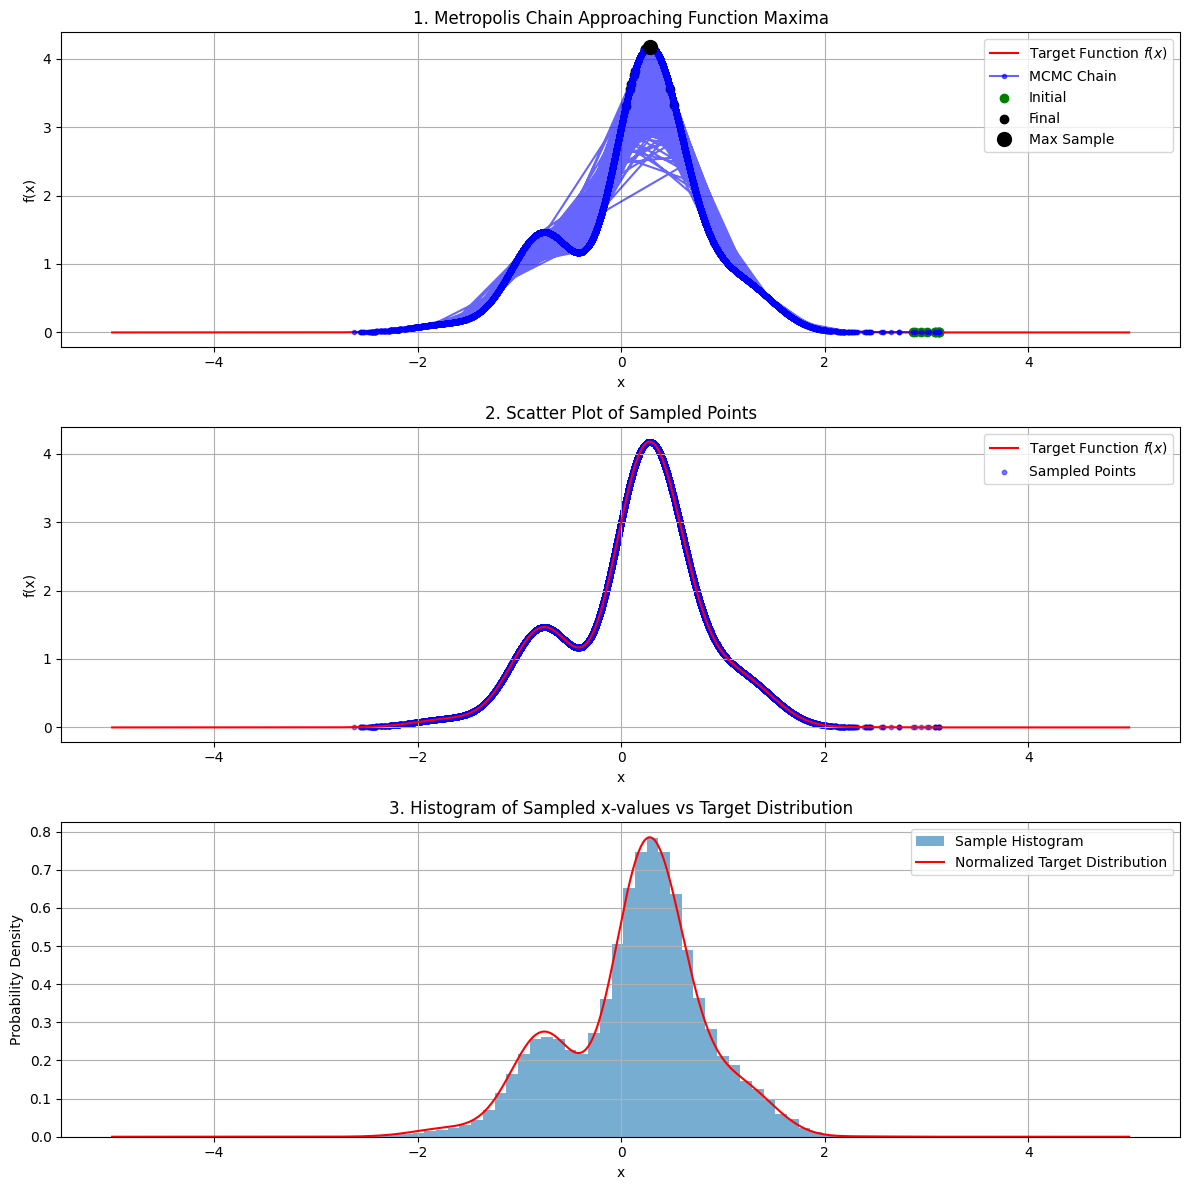

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

n = int(input("No of points you want to take: "))



def f(x):
    return np.exp(-x**2) * (3 + np.sin(5 * x) + np.sin(2 * x))


x1 = np.arange(-5, 5, 0.01)
y1 = f(x1)
# Metropolis Sampling
x_chain = []
y_chain = []
n_chain=[]
a_chain=[]

current = 3
f_current = f(current)
accept_count = 0

for i in range(1,n+1):
    proposal = current + np.random.normal(0, 0.2)
    f_proposal = f(proposal)
    alpha = f_proposal / f_current
    u = np.random.uniform(0,1)

    if alpha > 1 or u < alpha:
        current = proposal
        f_current = f_proposal
        accept_count += 1

    x_chain.append(current)
    y_chain.append(f_current)

    n_chain.append(accept_count)
    a_chain.append(proposal)



print(f"\nAcceptance Rate: {100 * accept_count / n:.2f}%")

plt.plot(n_chain,a_chain)
plt.grid()
plt.show()
# Max values
f_vals = f(x1)
max_f = np.max(f_vals)
max_x = x1[np.argmax(f_vals)]
print(f" True Maximum of f(x): {max_f:.4f} at x = {max_x:.4f}")

max_sample = np.max(y_chain)
max_sample_x = x_chain[np.argmax(y_chain)]
print(f" Max Sampled f(x): {max_sample:.4f} at x = {max_sample_x:.4f}")

# --- Subplot 1: Trajectory ---
plt.figure(figsize=(12, 12))

plt.subplot(3, 1, 1)
plt.plot(x1, y1, 'r-', label='Target Function $f(x)$')
plt.plot(x_chain, y_chain, 'b.-', alpha=0.6, label='MCMC Chain')
plt.scatter(x_chain[:10], y_chain[:10], color='green', label='Initial')
plt.scatter(x_chain[-10:], y_chain[-10:], color='black', label='Final')
plt.plot(max_sample_x, max_sample, 'ko', markersize=10, label='Max Sample')
plt.title('1. Metropolis Chain Approaching Function Maxima')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.legend()

# --- Subplot 2: Scatter Plot ---
plt.subplot(3, 1, 2)
plt.plot(x1, y1, 'r-', label='Target Function $f(x)$')
plt.scatter(x_chain, y_chain, s=10, color='blue', alpha=0.5, label='Sampled Points')
plt.title('2. Scatter Plot of Sampled Points')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.legend()

# --- Subplot 3: Histogram ---
plt.subplot(3, 1, 3)
plt.hist(x_chain, bins=50, density=True, alpha=0.6, label='Sample Histogram')
normalized_y1 = y1 / np.trapz(y1, x1)
plt.plot(x1, normalized_y1, 'r-', label='Normalized Target Distribution')
plt.title('3. Histogram of Sampled x-values vs Target Distribution')
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()
